# Calibration du label : horizon par client `H = k × p90`, périmètre rapides + moyens

**Question.** Le label « perdu » retenu est un horizon propre au client, `H_i = clip(k × écart p90, h_min, h_max)`, sur le périmètre des clients réguliers (rapides + moyens). Quels `k`, `h_min`, `h_max` choisir, et que vaut chaque choix **en CA** ?

**Principe en deux temps.**
1. *Vérité à long terme* : un client est « vraiment parti » s'il n'achète pas pendant **180 jours** après la photo. Elle sert d'étalon commun à toutes les règles.
2. *Label court pour entraîner* : chaque règle (`k`, `h_min`, `h_max`) définit un label `perdu si aucun achat avant H_i`. Comme `H_i ≤ 180`, tout vrai partant est aussi perdu au sens de la règle ; la règle ajoute des **faux perdus** (clients qui reviennent avant 180 jours). Un `h_max` court laisse plus de photos d'entraînement, un label plus bruité.

**Ce que le notebook mesure.**
- **A.** La distribution de `k × p90` : quel `h_max` est réaliste, combien de photos d'entraînement chaque `h_max` laisse.
- **B.** La pureté du label en CA (sans modèle) : part du CA « perdu » selon la règle qui est vraiment parti.
- **C.** Un modèle par règle (HistGradientBoosting), entraîné avec le label court, **évalué contre la vérité à 180 jours** sur une photo de test commune : CA capté, CA gaspillé, marge à rétention 10 / 20 / 30 %.

**Conventions.** Dates d'origine du dataset (22/09/2022 → 22/09/2024). Jour d'achat = CA net du jour > 0,01 €. Historique de 180 jours pour les variables et le rythme (les 6 premiers mois ne servent qu'à ça). Périmètre = au moins 6 jours d'achat sur 180 jours et écart médian ≤ 30 jours. `V` = CA des 180 jours précédents × 2 (CA annualisé). Montants en M€ **du périmètre du dataset**, non extrapolés. Photos mensuelles, du 22/03/2023 au 22/03/2024 ; la dernière sert de **test** (la seule dont les 180 jours de vérité tiennent encore dans les données).

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"        # reproductibilité : sommes en virgule flottante dans le même ordre à chaque exécution
from pathlib import Path
import time
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

pd.set_option("display.max_columns", 50, "display.width", 220, "display.float_format", lambda x: f"{x:,.3f}")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PARQUET = ROOT / "data" / "sales.parquet"

con = duckdb.connect()
con.execute("SET memory_limit='4GB'")
con.execute(f"SET temp_directory='{ROOT / 'data' / '.duckdb_tmp'}'")


def q(sql):
    return con.execute(sql).fetchdf()


# Palette du notebook d'exploration (une couleur = une entité, ordre fixe)
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", violet="#6250d6", yellow="#eda100", magenta="#e87ba4")
INK, INK2, MUTED, GRID, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
plt.rcParams.update({"axes.facecolor": SURF, "figure.facecolor": SURF, "axes.edgecolor": "#c3c2b7", "axes.grid": True,
                     "grid.color": GRID, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

### Paramètres (modifiables)

In [2]:
HIST = 180                 # jours d'historique pour les variables et le rythme
MIN_PURCH = 6              # jours d'achat minimum sur HIST
MED_GAP_MAX = 30           # écart médian maximum (rapides <= 7 j, moyens 8 à 30 j)
ANN = 2                    # annualisation du CA des 180 derniers jours
TRUTH_DAYS = 180           # vérité : « vraiment parti » = aucun achat pendant 180 jours
FIRST_T = pd.Timestamp("2023-03-22")
T_TEST = pd.Timestamp("2024-03-22")
ALL_DATES = [FIRST_T + pd.DateOffset(months=j) for j in range(13)]    # photos mensuelles, la dernière = test
assert ALL_DATES[-1] == T_TEST

K_GRID, HMIN_GRID, HMAX_GRID = (1.5, 2.0, 3.0, 4.0, 5.0), (30, 45), (60, 90, 120, 180)
K_LIST = (700, 2000)       # 700 ~ capacité mensuelle du dataset (600 à 760 appels) ; 2000 = K des tableaux précédents
MARGIN = 0.2465            # marge brute
RETENTIONS = (0.10, 0.20, 0.30)
N_BOOT = 200
SEED = 0

### Données : table (client, jour d'achat)

In [3]:
t0 = time.time()
con.execute(f"CREATE OR REPLACE VIEW sales AS SELECT * FROM read_parquet('{PARQUET}')")
con.execute("""
CREATE OR REPLACE TABLE bn AS
SELECT client_id, date_order AS d, sum(sales_net) AS rev
FROM sales WHERE date_order BETWEEN DATE '2022-09-22' AND DATE '2024-09-22'
GROUP BY 1, 2 HAVING sum(sales_net) > 0.01""")
DATA_END = pd.Timestamp(q("SELECT max(d) AS m FROM bn").iloc[0, 0])
print(f"{q('SELECT count(*) AS n FROM bn').iloc[0, 0]:,.0f} jours d'achat · fin des données {DATA_END:%d/%m/%Y} · {time.time() - t0:.0f}s")
assert T_TEST + pd.Timedelta(days=TRUTH_DAYS) <= DATA_END

7,792,993 jours d'achat · fin des données 22/09/2024 · 1s


### Une photo : variables avant T, prochain achat après T

In [4]:
FEATS = ["recency_days", "freq_180d", "freq_90d", "freq_prev_90d", "rev_180d", "rev_90d", "rev_prev_90d",
         "gap_median", "gap_p90", "recency_ratio", "freq_trend", "rev_trend"]


def photo(T: pd.Timestamp) -> pd.DataFrame:
    """One row per regular client (>= MIN_PURCH purchase days over HIST, median gap <= MED_GAP_MAX) at date T.
    Features use days strictly before T. `next_gap` = days from T to the next purchase day (NaN if none within 180 days)."""
    t = f"{T:%Y-%m-%d}"
    df = q(f"""
    WITH hist AS (SELECT client_id, d, rev, d - lag(d) OVER (PARTITION BY client_id ORDER BY d) AS gap
                  FROM bn WHERE d < DATE '{t}' AND d >= DATE '{t}' - {HIST}),
    agg AS (SELECT client_id, count(*) AS freq_180d, median(gap) AS gap_median, quantile_cont(gap, 0.9) AS gap_p90,
                   max(d) AS last_d, sum(rev) AS rev_180d,
                   count(*) FILTER (WHERE d >= DATE '{t}' - 90) AS freq_90d,
                   count(*) FILTER (WHERE d <  DATE '{t}' - 90) AS freq_prev_90d,
                   coalesce(sum(rev) FILTER (WHERE d >= DATE '{t}' - 90), 0) AS rev_90d,
                   coalesce(sum(rev) FILTER (WHERE d <  DATE '{t}' - 90), 0) AS rev_prev_90d
            FROM hist GROUP BY 1),
    fut AS (SELECT client_id, min(d) - DATE '{t}' AS next_gap FROM bn
            WHERE d >= DATE '{t}' AND d < DATE '{t}' + {TRUTH_DAYS} GROUP BY 1)
    SELECT a.*, date_diff('day', a.last_d, DATE '{t}') AS recency_days, f.next_gap
    FROM agg a LEFT JOIN fut f USING (client_id)""")
    df = df[(df.freq_180d >= MIN_PURCH) & (df.gap_median <= MED_GAP_MAX)].sort_values("client_id").copy()   # ordre fixe : DuckDB n'en garantit aucun
    df["V"] = ANN * df.rev_180d
    df["recency_ratio"] = df.recency_days / df.gap_p90.clip(lower=1)
    df["freq_trend"] = df.freq_90d / (df.freq_prev_90d + 1)
    df["rev_trend"] = df.rev_90d / (df.rev_prev_90d + 1)
    df["seg"] = np.where(df.gap_median <= 7, "Rapide", "Moyen")
    df["T"] = T
    df["gone"] = df.next_gap.isna().astype(int)        # no purchase within 180 days = vraiment parti
    return df.reset_index(drop=True)


t0 = time.time()
PH = {T: photo(T) for T in ALL_DATES}
print(f"{len(PH)} photos en {time.time() - t0:.0f}s")
pd.DataFrame({"Photo": [f"{T:%d/%m/%Y}" for T in PH], "Clients du périmètre": [len(d) for d in PH.values()],
              "CA annualisé (M)": [d.V.sum() / 1e6 for d in PH.values()],
              "Vraiment partis (%)": [100 * d.gone.mean() for d in PH.values()],
              "CA vraiment parti (M)": [(d.V * d.gone).sum() / 1e6 for d in PH.values()]}).set_index("Photo")

13 photos en 2s


,Clients du périmètre,CA annualisé (M),Vraiment partis (%),CA vraiment parti (M)
Photo,,,,
22/03/2023,62239,"4,458.318",3.822,59.842
22/04/2023,61394,"4,416.068",3.880,74.883
22/05/2023,59003,"4,075.150",3.476,60.533
22/06/2023,59074,"4,118.182",3.438,60.401
22/07/2023,59641,"4,199.599",3.568,60.769
22/08/2023,60331,"4,256.966",3.703,56.906
22/09/2023,60312,"4,194.633",3.996,65.302
22/10/2023,60624,"4,195.563",3.954,68.833
22/11/2023,62590,"4,523.664",4.699,86.552


## A. Quelle distribution pour `k × p90` ? Quel `h_max` est réaliste ?

La dernière photo d'entraînement utilisable est `T_test − h_max` : le label le plus long d'un client d'entraînement doit être connu avant la date de test. Plus `h_max` est grand, moins il reste de photos. Ci-dessous, `k × p90` **non borné**, sur les 12 photos d'avant le test (empilées), pondéré par le client ou par son CA.

In [5]:
POOL = pd.concat([PH[T] for T in ALL_DATES[:-1]], ignore_index=True)
rows = []
for k in K_GRID:
    h = k * POOL.gap_p90
    row = {"k": k}
    for p in (50, 75, 90, 95, 99):
        row[f"H p{p} (j)"] = np.percentile(h, p)
    for thr in (60, 90, 120, 180):
        row[f"> {thr} j (% clients)"] = 100 * (h > thr).mean()
        row[f"> {thr} j (% CA)"] = 100 * POOL.V[h > thr].sum() / POOL.V.sum()
    rows.append(row)
dist = pd.DataFrame(rows).set_index("k")
dist

,H p50 (j),H p75 (j),H p90 (j),H p95 (j),H p99 (j),> 60 j (% clients),> 60 j (% CA),> 90 j (% clients),> 90 j (% CA),> 120 j (% clients),> 120 j (% CA),> 180 j (% clients),> 180 j (% CA)
k,,,,,,,,,,,,,
1.500,26.250,45.600,66.000,78.600,101.250,13.373,2.067,2.339,0.301,0.158,0.020,0.000,0.000
2.000,35.000,60.800,88.000,104.800,135.000,25.413,4.504,9.208,1.347,2.339,0.301,0.024,0.003
3.000,52.500,91.200,132.000,157.200,202.500,44.076,9.998,25.413,4.504,13.373,2.067,2.339,0.301
4.000,70.000,121.600,176.000,209.600,270.000,55.219,14.609,38.513,8.082,25.413,4.504,9.208,1.347
5.000,87.500,152.000,220.000,262.000,337.500,64.693,20.012,48.676,11.760,35.646,7.202,17.525,2.851


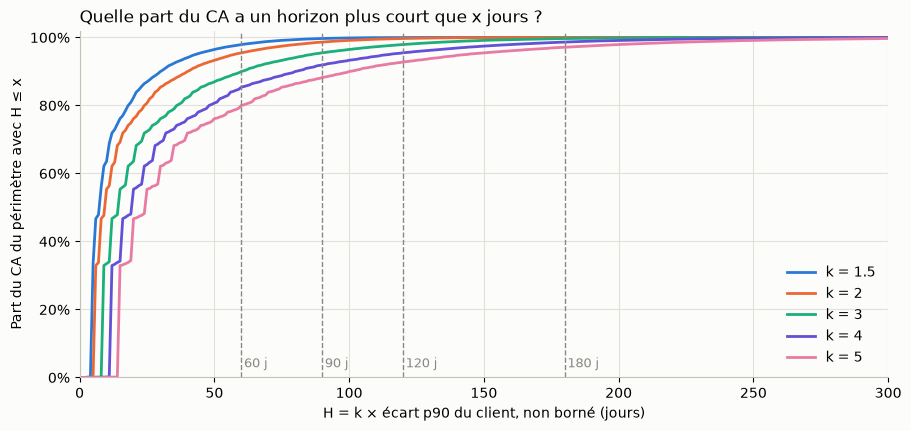

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.2), constrained_layout=True)
xs = np.arange(0, 301)
for (k, col) in zip(K_GRID, (C["blue"], C["orange"], C["aqua"], C["violet"], C["magenta"])):
    h = (k * POOL.gap_p90).to_numpy()
    o = np.argsort(h)
    cum = np.cumsum(POOL.V.to_numpy()[o]) / POOL.V.sum()
    y = np.interp(xs, h[o], cum)
    ax.plot(xs, y * 100, color=col, lw=2, label=f"k = {k:g}")
for thr in (60, 90, 120, 180):
    ax.axvline(thr, color=MUTED, ls="--", lw=1)
    ax.text(thr + 1, 3, f"{thr} j", color=MUTED, fontsize=9)
ax.set_xlim(0, 300)
ax.set_ylim(0, 102)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlabel("H = k × écart p90 du client, non borné (jours)")
ax.set_ylabel("Part du CA du périmètre avec H ≤ x")
ax.set_title("Quelle part du CA a un horizon plus court que x jours ?", loc="left")
ax.legend(frameon=False, loc="lower right")
plt.show()

In [7]:
rows = []
for hmax in (60, 90, 120, 180):
    train = [T for T in ALL_DATES[:-1] if (T_TEST - T).days >= hmax]
    clipped = {f"k={k:g} : CA dont k×p90 > h_max (%)": 100 * POOL.V[k * POOL.gap_p90 > hmax].sum() / POOL.V.sum() for k in K_GRID}
    rows.append({"h_max (j)": hmax, "Photos d'entraînement": len(train),
                 "Dernière photo d'entraînement": f"{max(train):%d/%m/%Y}", **clipped})
pd.DataFrame(rows).set_index("h_max (j)")

,Photos d'entraînement,Dernière photo d'entraînement,k=1.5 : CA dont k×p90 > h_max (%),k=2 : CA dont k×p90 > h_max (%),k=3 : CA dont k×p90 > h_max (%),k=4 : CA dont k×p90 > h_max (%),k=5 : CA dont k×p90 > h_max (%)
h_max (j),,,,,,,
60,11,22/01/2024,2.067,4.504,9.998,14.609,20.012
90,10,22/12/2023,0.301,1.347,4.504,8.082,11.760
120,9,22/11/2023,0.020,0.301,2.067,4.504,7.202
180,7,22/09/2023,0.000,0.003,0.301,1.347,2.851


## B. Pureté du label en CA (sans modèle)

Pour chaque règle, sur chacune des 13 photos : `perdu` = aucun achat avant `H_i`. La **vérité** = aucun achat pendant 180 jours. Comme `H_i ≤ 180`, `vraiment parti ⊂ perdu`.

- **Pureté (CA)** = CA des vrais partants ÷ CA des clients déclarés perdus. À 100 %, le label ne se trompe jamais.
- **CA faux perdu** = CA des clients déclarés perdus qui rachètent avant 180 jours : c'est du CA que le label compte comme perdu à tort.
- **Déjà au-delà de H** : clients dont la récence à la date de la photo dépasse déjà leur `H_i` (leur label est presque joué d'avance) ; part du CA, et part d'entre eux qui part vraiment.

In [8]:
def horizon(df, rule):
    """rule = ('common', 180) or (k, h_min, h_max)."""
    if rule[0] == "common":
        return pd.Series(float(rule[1]), index=df.index)
    k, hmin, hmax = rule
    return (k * df.gap_p90).clip(hmin, hmax)


def label(df, rule):
    return (df.next_gap.fillna(9999) >= horizon(df, rule)).astype(int)


def rule_name(rule):
    return "H = 180 j pour tous" if rule[0] == "common" else f"k={rule[0]:g} · h_min={rule[1]} · h_max={rule[2]}"


RULES = [("common", 180)] + [(k, hmin, hmax) for hmax in HMAX_GRID for k in K_GRID for hmin in HMIN_GRID]

rows = []
for rule in RULES:
    pur, fl, lost_ca, gone_ca, share_lost, late_ca, late_gone = [], [], [], [], [], [], []
    for T in ALL_DATES:
        d = PH[T]
        L, Y, H = label(d, rule), d.gone, horizon(d, rule)
        assert (Y <= L).all()
        pur.append((d.V * Y).sum() / (d.V * L).sum())
        fl.append((d.V * (L - Y)).sum() / 1e6)
        lost_ca.append((d.V * L).sum() / 1e6)
        gone_ca.append((d.V * Y).sum() / 1e6)
        share_lost.append(L.mean())
        late = d.recency_days > H
        late_ca.append(d.V[late].sum() / d.V.sum())
        late_gone.append((d.V[late] * Y[late]).sum() / max(d.V[late].sum(), 1))
    rows.append({"Règle": rule_name(rule), "Clients déclarés perdus (%)": 100 * np.mean(share_lost),
                 "CA déclaré perdu (M/photo)": np.mean(lost_ca), "CA vraiment parti (M/photo)": np.mean(gone_ca),
                 "Pureté (CA, %)": 100 * np.mean(pur), "Pureté min (%)": 100 * np.min(pur), "Pureté max (%)": 100 * np.max(pur),
                 "CA faux perdu (M/photo)": np.mean(fl),
                 "Déjà au-delà de H (% CA)": 100 * np.mean(late_ca), "… dont vraiment partis (% CA)": 100 * np.mean(late_gone)})
purity = pd.DataFrame(rows).set_index("Règle")
purity

,Clients déclarés perdus (%),CA déclaré perdu (M/photo),CA vraiment parti (M/photo),"Pureté (CA, %)",Pureté min (%),Pureté max (%),CA faux perdu (M/photo),Déjà au-delà de H (% CA),… dont vraiment partis (% CA)
Règle,,,,,,,,,
H = 180 j pour tous,3.913,66.748,66.748,100.000,100.000,100.000,0.000,0.000,0.000
k=1.5 · h_min=30 · h_max=60,13.750,180.968,66.748,38.240,22.608,47.729,114.220,2.807,34.405
k=1.5 · h_min=45 · h_max=60,11.719,143.669,66.748,47.179,34.805,56.458,76.921,1.803,42.571
k=2 · h_min=30 · h_max=60,12.195,163.446,66.748,42.237,25.971,51.470,96.698,2.387,38.846
k=2 · h_min=45 · h_max=60,11.062,137.638,66.748,49.222,35.912,58.049,70.890,1.661,45.136
k=3 · h_min=30 · h_max=60,10.811,142.863,66.748,47.865,33.620,56.937,76.116,1.884,44.950
k=3 · h_min=45 · h_max=60,10.425,130.168,66.748,52.005,37.451,60.582,63.420,1.476,48.290
k=4 · h_min=30 · h_max=60,10.385,134.496,66.748,50.611,36.356,59.840,67.748,1.653,48.335
k=4 · h_min=45 · h_max=60,10.204,126.847,66.748,53.339,38.297,61.995,60.099,1.386,49.887


## C. Un modèle par règle, évalué contre la vérité à 180 jours

Pour chaque règle : photos d'entraînement = celles dont la date vérifie `T ≤ T_test − h_max` (donc dont tous les labels sont connus avant le test), label = règle, modèle HistGradientBoosting (12 variables, sans calibration car on classe seulement). **Test commun : photo du 22/03/2024, évaluée sur la vérité à 180 jours**, donc comparable d'une règle à l'autre.

Pour la liste de K clients les mieux classés :
- **CA capté** = CA des vrais partants dans la liste ÷ CA de tous les vrais partants ;
- **CA gaspillé** = CA des clients de la liste qui ne partent pas (appels qui n'étaient pas nécessaires) ;
- **Marge** = `r × 24,65 % × CA des vrais partants dans la liste`, pour r = 10 / 20 / 30 % (lecture « CA capté », sans action aujourd'hui) ;
- IC 95 % par bootstrap des clients du test (200 tirages, mêmes tirages pour toutes les règles, donc écarts avec la référence appariés).

In [9]:
TEST = PH[T_TEST].copy()
V_T, Y_T = TEST.V.to_numpy(), TEST.gone.to_numpy()
LOSS_T = V_T * Y_T


def train_rule(rule, seed=SEED):
    hmax = rule[1] if rule[0] == "common" else rule[2]
    dates = [T for T in ALL_DATES[:-1] if (T_TEST - T).days >= hmax]
    tr = pd.concat([PH[T] for T in dates], ignore_index=True)
    y = label(tr, rule)
    model = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.08, early_stopping=False, random_state=seed)
    model.fit(tr[FEATS], y)
    return model.predict_proba(TEST[FEATS])[:, 1], len(dates), len(tr), y.mean()


def top_k_mask(score, K):
    idx = np.argpartition(-score, K - 1)[:K]
    return idx


t0 = time.time()
SCORES, META = {}, {}
for rule in RULES:
    s, n_ph, n_rows, base = train_rule(rule)
    SCORES[rule] = s
    META[rule] = (n_ph, n_rows, base)
    print(f"{rule_name(rule):38s} photos={n_ph:2d} lignes={n_rows:>8,d} taux de perdus={base:5.1%} ({time.time() - t0:.0f}s)")
# Repères sans modèle
SCORES[("base", "récence ÷ p90")] = TEST.recency_ratio.to_numpy()
SCORES[("base", "plus gros clients")] = np.ones(len(TEST))     # le classement par valeur est appliqué plus bas

H = 180 j pour tous                    photos= 7 lignes= 421,994 taux de perdus= 3.7% (4s)


k=1.5 · h_min=30 · h_max=60            photos=11 lignes= 670,386 taux de perdus=13.7% (9s)


k=1.5 · h_min=45 · h_max=60            photos=11 lignes= 670,386 taux de perdus=11.6% (15s)


k=2 · h_min=30 · h_max=60              photos=11 lignes= 670,386 taux de perdus=12.1% (21s)


k=2 · h_min=45 · h_max=60              photos=11 lignes= 670,386 taux de perdus=10.9% (27s)


k=3 · h_min=30 · h_max=60              photos=11 lignes= 670,386 taux de perdus=10.7% (32s)


... (31 outputs left out)

k=4 · h_min=30 · h_max=180             photos= 7 lignes= 421,994 taux de perdus= 5.7% (180s)


k=4 · h_min=45 · h_max=180             photos= 7 lignes= 421,994 taux de perdus= 5.5% (184s)


k=5 · h_min=30 · h_max=180             photos= 7 lignes= 421,994 taux de perdus= 5.0% (187s)


k=5 · h_min=45 · h_max=180             photos= 7 lignes= 421,994 taux de perdus= 4.8% (191s)


In [10]:
# Deux classements de la même probabilité : par valeur espérée (p x V, celui du projet) et par probabilité seule (p)
RANKS = {"VE": {r: sc * V_T for r, sc in SCORES.items()}, "p": dict(SCORES)}
RANKS["p"][("base", "plus gros clients")] = V_T
RANKS["VE"][("base", "plus gros clients")] = V_T

rng = np.random.default_rng(SEED)
n = len(TEST)
boot_idx = [rng.integers(0, n, n) for _ in range(N_BOOT)]
REF = ("common", 180)


def capture(score, loss, K, idx=None):
    if idx is not None:
        score, loss = score[idx], loss[idx]
    top = np.argpartition(-score, K - 1)[:K]
    return loss[top].sum() / loss.sum()


res = {}
for rk, sc_all in RANKS.items():
    BS_REF = {K: np.array([capture(sc_all[REF], LOSS_T, K, ix) for ix in boot_idx]) for K in K_LIST}
    for rule, s in sc_all.items():
        for K in K_LIST:
            pt = capture(s, LOSS_T, K)
            bs = BS_REF[K] if rule == REF else np.array([capture(s, LOSS_T, K, ix) for ix in boot_idx])
            diff = bs - BS_REF[K]
            res[(rk, rule, K)] = dict(point=pt, lo=np.percentile(bs, 2.5), hi=np.percentile(bs, 97.5),
                                      d_lo=np.percentile(diff, 2.5), d_hi=np.percentile(diff, 97.5),
                                      d=pt - capture(sc_all[REF], LOSS_T, K))
print("bootstrap terminé")

bootstrap terminé


In [11]:
def label_of(rule):
    return rule_name(rule) if rule[0] in ("common",) or isinstance(rule[0], float) else f"[repère] {rule[1]}"


def build_table(rk):
    rows = []
    for rule, s in RANKS[rk].items():
        n_ph, n_rows, base = META.get(rule, (np.nan, np.nan, np.nan))
        row = {"Règle": label_of(rule), "Photos d'entraînement": n_ph, "Taux de perdus à l'entraînement (%)": 100 * base,
               "AUC (p) vs vérité": roc_auc_score(Y_T, SCORES[rule]) if rule[0] != "base" or rule[1] != "plus gros clients" else roc_auc_score(Y_T, V_T)}
        for K in K_LIST:
            top = np.argpartition(-s, K - 1)[:K]
            r = res[(rk, rule, K)]
            row[f"K={K} CA capté (%)"] = 100 * r["point"]
            row[f"K={K} IC 95 % (%)"] = f"[{100 * r['lo']:.0f}–{100 * r['hi']:.0f}]"
            row[f"K={K} écart vs 180 j (pts)"] = 100 * r["d"]
            row[f"K={K} IC de l'écart"] = f"[{100 * r['d_lo']:+.0f} ; {100 * r['d_hi']:+.0f}]"
            row[f"K={K} CA gaspillé (M)"] = (V_T[top] * (1 - Y_T[top])).sum() / 1e6
            row[f"K={K} appels sur vrais partants (%)"] = 100 * Y_T[top].mean()
            for rr in RETENTIONS:
                row[f"K={K} marge r={rr:.0%} (M€)"] = rr * MARGIN * LOSS_T[top].sum() / 1e6
        rows.append(row)
    return pd.DataFrame(rows).set_index("Règle")


results = build_table("VE")
results_p = build_table("p")
print(f"CA vraiment parti sur la photo de test : {LOSS_T.sum() / 1e6:,.1f} M ({int(Y_T.sum()):,} clients sur {len(TEST):,})")
cols_k = lambda df, K: [c for c in df.columns if c.startswith(f"K={K}")]
print("Classement par valeur espérée p x V, K =", K_LIST[0])
results[["Photos d'entraînement", "Taux de perdus à l'entraînement (%)", "AUC (p) vs vérité"] + cols_k(results, K_LIST[0])]

CA vraiment parti sur la photo de test : 60.7 M (2,226 clients sur 61,286)
Classement par valeur espérée p x V, K = 700


,Photos d'entraînement,Taux de perdus à l'entraînement (%),AUC (p) vs vérité,K=700 CA capté (%),K=700 IC 95 % (%),K=700 écart vs 180 j (pts),K=700 IC de l'écart,K=700 CA gaspillé (M),K=700 appels sur vrais partants (%),K=700 marge r=10% (M€),K=700 marge r=20% (M€),K=700 marge r=30% (M€)
Règle,,,,,,,,,,,,
H = 180 j pour tous,7.000,3.700,0.892,48.757,[43–55],0.000,[+0 ; +0],108.019,49.000,0.730,1.460,2.190
k=1.5 · h_min=30 · h_max=60,11.000,13.711,0.886,48.441,[42–54],-0.316,[-2 ; +2],87.116,40.000,0.725,1.450,2.175
k=1.5 · h_min=45 · h_max=60,11.000,11.577,0.888,47.740,[42–54],-1.016,[-3 ; +1],90.673,41.286,0.715,1.429,2.144
k=2 · h_min=30 · h_max=60,11.000,12.108,0.890,49.059,[43–55],0.302,[-2 ; +2],81.784,41.571,0.734,1.469,2.203
k=2 · h_min=45 · h_max=60,11.000,10.913,0.889,48.465,[42–54],-0.292,[-3 ; +2],79.791,43.429,0.725,1.451,2.176
k=3 · h_min=30 · h_max=60,11.000,10.683,0.892,49.263,[43–55],0.507,[-1 ; +2],76.783,44.714,0.737,1.475,2.212
k=3 · h_min=45 · h_max=60,11.000,10.268,0.890,48.885,[42–55],0.128,[-2 ; +2],84.165,43.429,0.732,1.464,2.195
k=4 · h_min=30 · h_max=60,11.000,10.237,0.891,49.593,[44–56],0.836,[-1 ; +4],70.619,44.714,0.742,1.485,2.227
k=4 · h_min=45 · h_max=60,11.000,10.042,0.890,49.164,[43–55],0.407,[-1 ; +2],71.356,45.429,0.736,1.472,2.208


In [12]:
print("Classement par valeur espérée p x V, K =", K_LIST[1])
results[["Photos d'entraînement", "AUC (p) vs vérité"] + cols_k(results, K_LIST[1])]

Classement par valeur espérée p x V, K = 2000


,Photos d'entraînement,AUC (p) vs vérité,K=2000 CA capté (%),K=2000 IC 95 % (%),K=2000 écart vs 180 j (pts),K=2000 IC de l'écart,K=2000 CA gaspillé (M),K=2000 appels sur vrais partants (%),K=2000 marge r=10% (M€),K=2000 marge r=20% (M€),K=2000 marge r=30% (M€)
Règle,,,,,,,,,,,
H = 180 j pour tous,7.000,0.892,64.841,[60–70],0.000,[+0 ; +0],184.991,34.550,0.971,1.941,2.912
k=1.5 · h_min=30 · h_max=60,11.000,0.886,63.501,[58–69],-1.341,[-4 ; +1],189.796,27.350,0.951,1.901,2.852
k=1.5 · h_min=45 · h_max=60,11.000,0.888,64.207,[59–69],-0.635,[-3 ; +1],183.310,29.200,0.961,1.922,2.883
k=2 · h_min=30 · h_max=60,11.000,0.890,64.801,[60–70],-0.041,[-1 ; +1],194.803,28.950,0.970,1.940,2.910
k=2 · h_min=45 · h_max=60,11.000,0.889,64.538,[60–69],-0.303,[-2 ; +1],189.041,30.100,0.966,1.932,2.898
k=3 · h_min=30 · h_max=60,11.000,0.892,65.727,[61–71],0.886,[-0 ; +2],174.010,30.700,0.984,1.968,2.952
k=3 · h_min=45 · h_max=60,11.000,0.890,65.460,[60–70],0.618,[-1 ; +2],178.517,30.550,0.980,1.960,2.940
k=4 · h_min=30 · h_max=60,11.000,0.891,65.817,[61–71],0.975,[+0 ; +2],161.519,30.900,0.985,1.970,2.956
k=4 · h_min=45 · h_max=60,11.000,0.890,65.503,[61–70],0.662,[-0 ; +2],167.269,30.650,0.981,1.961,2.942


In [13]:
# Comparaison : classement par probabilité seule (sans multiplier par V), CA capté uniquement
cmp = pd.DataFrame({f"K={K} {name} (%)": 100 * pd.Series({label_of(r): res[(rk, r, K)]["point"] for r in SCORES}) for K in K_LIST
                    for rk, name in (("VE", "p×V"), ("p", "p seul"))})
cmp

,K=700 p×V (%),K=700 p seul (%),K=2000 p×V (%),K=2000 p seul (%)
H = 180 j pour tous,48.757,33.566,64.841,46.022
k=1.5 · h_min=30 · h_max=60,48.441,31.986,63.501,43.679
k=1.5 · h_min=45 · h_max=60,47.740,32.229,64.207,44.189
k=2 · h_min=30 · h_max=60,49.059,31.495,64.801,45.117
k=2 · h_min=45 · h_max=60,48.465,32.733,64.538,44.288
k=3 · h_min=30 · h_max=60,49.263,32.847,65.727,46.059
k=3 · h_min=45 · h_max=60,48.885,32.324,65.460,43.879
k=4 · h_min=30 · h_max=60,49.593,33.380,65.817,45.360
k=4 · h_min=45 · h_max=60,49.164,32.872,65.503,44.691
k=5 · h_min=30 · h_max=60,48.968,33.350,65.354,45.136


### Bruit d'entraînement : même règle, 5 graines différentes

Les écarts entre règles ne valent que s'ils dépassent l'écart qu'on obtient en réentraînant **la même règle** avec une autre graine (le sous-échantillonnage utilisé pour découper les variables en classes change le modèle).

In [14]:
N_SEEDS = 5
rows = []
for rule in (REF, (3.0, 45, 90), (4.0, 45, 90), (5.0, 45, 90), (4.0, 45, 120), (5.0, 45, 120), (5.0, 45, 180)):
    caps = {K: [] for K in K_LIST}
    for sd in range(N_SEEDS):
        s_, *_ = train_rule(rule, seed=sd)
        for K in K_LIST:
            caps[K].append(100 * capture(s_ * V_T, LOSS_T, K))
    row = {"Règle": rule_name(rule)}
    for K in K_LIST:
        row[f"K={K} moyenne (%)"] = np.mean(caps[K])
        row[f"K={K} min–max (%)"] = f"{np.min(caps[K]):.1f} – {np.max(caps[K]):.1f}"
        row[f"K={K} écart-type (pts)"] = np.std(caps[K], ddof=1)
    rows.append(row)
seeds_tab = pd.DataFrame(rows).set_index("Règle")
seeds_tab

,K=700 moyenne (%),K=700 min–max (%),K=700 écart-type (pts),K=2000 moyenne (%),K=2000 min–max (%),K=2000 écart-type (pts)
Règle,,,,,,
H = 180 j pour tous,49.222,48.3 – 50.2,0.798,64.998,64.7 – 65.4,0.331
k=3 · h_min=45 · h_max=90,50.954,50.5 – 51.5,0.409,65.452,65.2 – 66.0,0.325
k=4 · h_min=45 · h_max=90,50.436,50.2 – 50.8,0.280,65.586,65.0 – 66.2,0.520
k=5 · h_min=45 · h_max=90,50.323,49.9 – 50.8,0.351,65.884,65.1 – 67.5,0.948
k=4 · h_min=45 · h_max=120,49.867,47.9 – 51.1,1.283,64.505,63.8 – 65.3,0.664
k=5 · h_min=45 · h_max=120,49.163,46.7 – 51.0,2.030,65.010,64.7 – 65.7,0.388
k=5 · h_min=45 · h_max=180,50.311,49.9 – 51.5,0.686,64.528,63.7 – 65.3,0.629


### Graphique : CA capté, par règle (K = 700, classement p × V)

Un point par règle, avec son IC 95 % ; les repères sans modèle en gris. Plus à droite = plus de CA de vrais partants dans la liste.

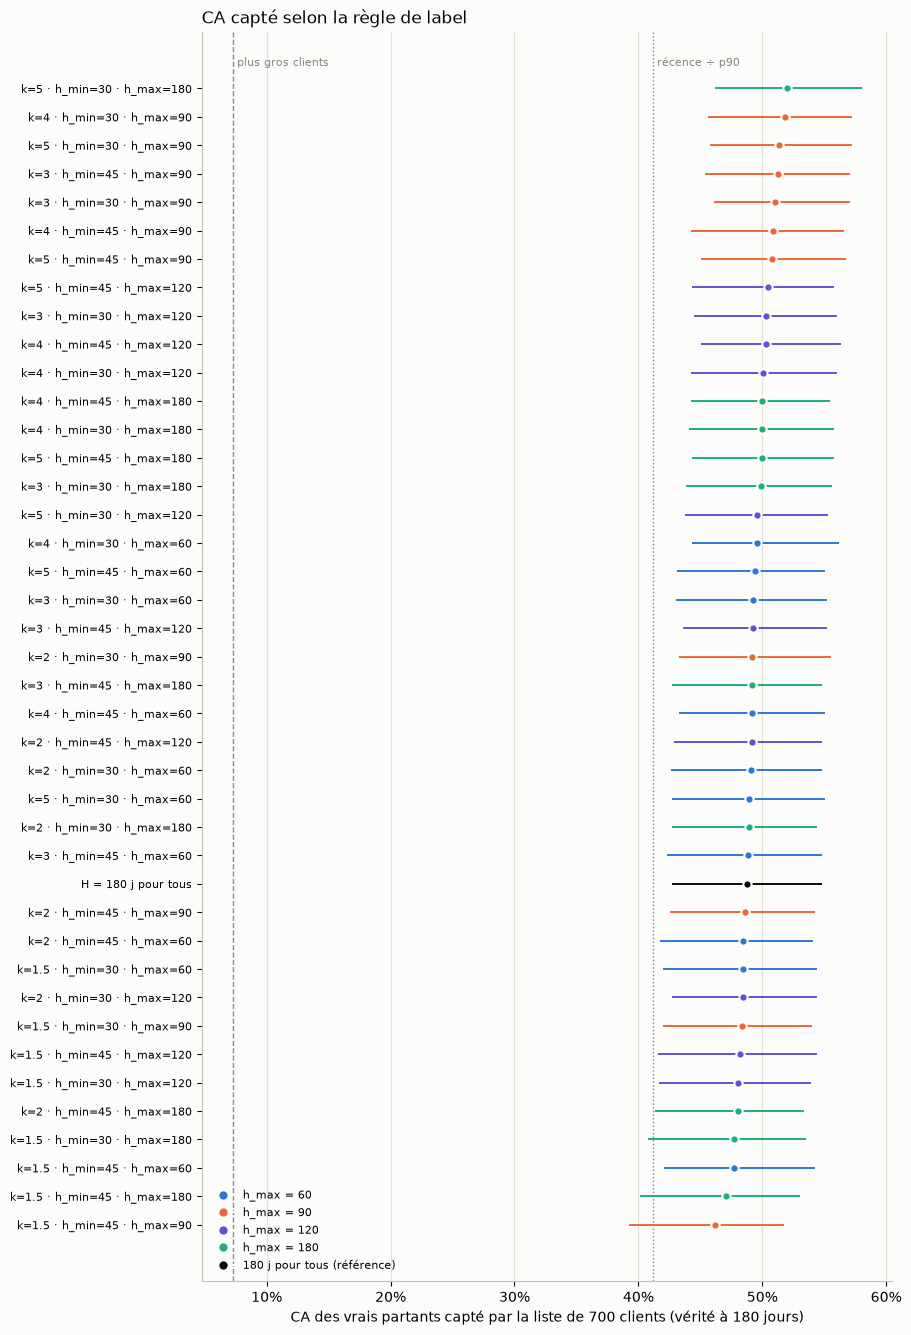

In [15]:
K0 = K_LIST[0]
order = [r for r in SCORES if r[0] != "base"]
order = sorted(order, key=lambda r: res[("VE", r, K0)]["point"])
col_of = {60: C["blue"], 90: C["orange"], 120: C["violet"], 180: C["aqua"]}
fig, ax = plt.subplots(figsize=(9, 0.28 * (len(order) + 2) + 1.2), constrained_layout=True)
for i, r in enumerate(order):
    v = res[("VE", r, K0)]
    c = INK if r[0] == "common" else col_of[r[2]]
    ax.plot([100 * v["lo"], 100 * v["hi"]], [i, i], color=c, lw=1.4)
    ax.plot(100 * v["point"], i, "o", color=c, ms=6, mec=SURF, mew=1.5)
ax.set_yticks(range(len(order)))
ax.set_yticklabels([rule_name(r) for r in order], fontsize=8)
for rr, ls in (("récence ÷ p90", ":"), ("plus gros clients", "--")):
    x = 100 * res[("VE", ("base", rr), K0)]["point"]
    ax.axvline(x, color=MUTED, ls=ls, lw=1)
    ax.text(x, len(order) - 0.3, f" {rr}", color=MUTED, fontsize=8, va="bottom")
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlabel(f"CA des vrais partants capté par la liste de {K0} clients (vérité à 180 jours)")
ax.set_title("CA capté selon la règle de label", loc="left")
ax.grid(axis="y", visible=False)
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([], [], marker="o", color="w", mfc=c, ms=7, label=l) for l, c in
                   (("h_max = 60", C["blue"]), ("h_max = 90", C["orange"]), ("h_max = 120", C["violet"]), ("h_max = 180", C["aqua"]), ("180 j pour tous (référence)", INK))],
          frameon=False, loc="lower left", fontsize=8)
plt.show()

## Conclusions (photo de test du 22/03/2024, périmètre du dataset ; calcul reproductible, 41 règles)

**Ce que les données établissent (A et B, calculs directs, sans modèle).**
1. **`h_max = 180` laisse 7 photos d'entraînement, contre 10 à `h_max = 90` et 11 à 60.** Le plafond borne d'autant plus de CA que `k` est grand : à `h_max = 90`, 1,3 % du CA à `k = 2`, 4,5 % à `k = 3`, 8,1 % à `k = 4`, 11,8 % à `k = 5`.
2. **Le label court déclare « perdu » 1,3 à 2,7 fois plus de CA que ce qui part vraiment** (87 à 181 M€ par photo pour 66,7 M€). La pureté en CA (38 à 77 %) monte avec `k`, `h_min` et `h_max`. À `h_min = 45`, `h_max = 90` : 59,5 % pour `k = 3`, 63,9 % pour `k = 4`, 66,7 % pour `k = 5`. **Ce CA « perdu » n'est pas du CA récupérable** : toute évaluation en CA se fait contre la vérité à 180 jours (borne elle-même : un client qui revient au jour 200 compte comme parti).
3. **Les clients déjà au-delà de leur `H` à la date de la photo** (1,2 à 2,8 % du CA avec `k ≤ 3`) partent vraiment dans 34 à 53 % des cas, contre ≈ 1,5 % du CA en moyenne : on les garde.

**Ce que le modèle montre (C) : une petite avance, pas un écart net.**
4. **Direction constante : `k ≥ 3` avec `h_max = 90`.** Les six règles `k ∈ {3, 4, 5}`, `h_min ∈ {30, 45}`, `h_max = 90` sont au-dessus de la référence aux deux K : +2,1 à +3,1 points à K = 700, +0,7 à +1,6 point à K = 2 000. Seule `k = 4`, `h_min = 30` exclut zéro aux deux K (+3,1 [+1 ; +5] et +1,6 [+1 ; +3]). `k = 1,5` est en dessous (jusqu'à −2,6 points [−5 ; −1]). Les plafonds 120 et 180 sont mitigés : positifs à K = 700, négatifs ou nuls à K = 2 000.
5. **Mais le bruit d'entraînement est du même ordre.** Réentraîner la même règle avec 5 graines fait varier le CA capté de 0,3 à 2 points (écart-type) ; l'IC 95 % d'une règle fait ± 5 points. Moyenne de 5 graines : `k = 3`, `h_min = 45`, `h_max = 90` à 51,0 % contre 49,2 % pour la référence à K = 700, 65,5 % contre 65,0 % à K = 2 000.
6. **En euros, l'avance est petite.** Marge à r = 20 % : de 1,38 à 1,56 M€ par an à K = 700 (référence : 1,46), de 1,86 à 1,99 M€ à K = 2 000 (référence : 1,94). La meilleure règle gagne ≈ 0,05 à 0,09 M€ par an, soit environ 3 à 6 %. Le label est un levier de second ordre, bien après le classement et la rétention.
7. **Le classement compte beaucoup plus que le label.** `p × V` capte ≈ 48 % à K = 700 contre ≈ 32 % en classant par probabilité seule (+15 points) ; le repère « récence ÷ p90 × V » sans modèle : 41 %.

**Recommandation : `k = 3`, `h_min = 45`, `h_max = 90`**, règle fixée avant d'avoir vu `k = 4` et 5, ce qui évite de prendre le meilleur de 41 tirages (le meilleur d'un lot est biaisé vers le haut). `k = 4` est équivalent aux erreurs de mesure près, avec une pureté plus haute (63,9 %) mais 8 % du CA borné. Entraînement du 22/03/2023 au 22/12/2023 (10 photos) ; chiffre annoncé contre la vérité à 180 jours.

**Limites.** Une seule photo de test et une seule saison (mars à septembre 2024). 41 règles comparées sur la même photo : l'avance de 1 à 3 points n'est pas démontrée au sens strict. La probabilité brute d'un label court n'est pas calibrée sur la vérité, ce qui joue dans `p × V`. La colonne « CA gaspillé » (CA annualisé des clients appelés qui restent) est dominée par les gros clients et ne sert pas à décider ; « appels sur vrais partants » est plus parlante.